# CCE3206 - Digital Signal Processing
## Practical 2: Discrete Time Signals
**Name:** Dave Galea
**Student ID:** 0283404L

## Task 1

In [43]:
import numpy as np
def iir_filter(x):
    # set y to have the same length and type as x
    y = np.zeros_like(x, dtype=float)
    # iterate over all input samples
    w_n_minus_1 = 0

    # compute y(n) and store it in y[n]
    for n, x_n in enumerate(x):
        w_n = (0.6 * w_n_minus_1) + x_n
        y_n = (0.2 * w_n_minus_1) + (0.2 * w_n)
        y[n] = y_n
        w_n_minus_1 = w_n

    return y # return the array 

## Task 2

### a)

In [44]:
x_n = np.zeros(10)
x_n[0] = 1 

### b)

In [45]:
y_n = iir_filter(x_n)

### c)

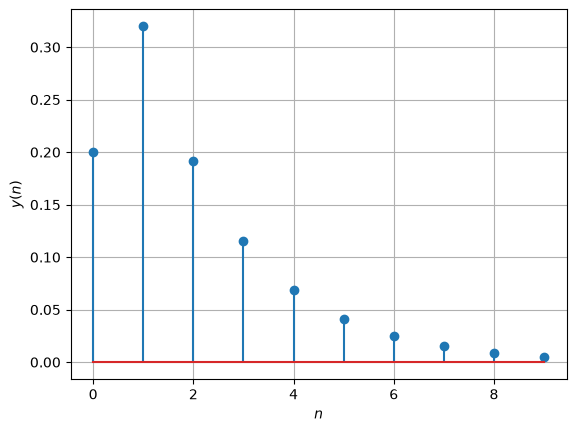

In [46]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
n = np.arange(len(y_n))
ax.stem(n, y_n)
ax.set_xlabel('$n$')
ax.set_ylabel('$y(n)$')
plt.grid()
plt.show()

## Task 3 

### a)

In [47]:
x_n = np.ones(20)

### b)

In [48]:
y_n = iir_filter(x_n)

### c)

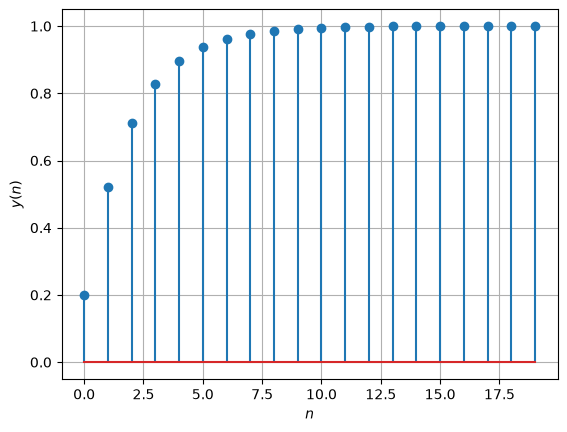

In [49]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
n = np.arange(len(y_n))
ax.stem(n, y_n)
ax.set_xlabel('$n$')
ax.set_ylabel('$y(n)$')
plt.grid()
plt.show()

## Task 4 

### a)

In [50]:
x_n = np.zeros(20)
x_n[0:10] = np.ones(10)

### b)

In [51]:
y_n = iir_filter(x_n)

### c)

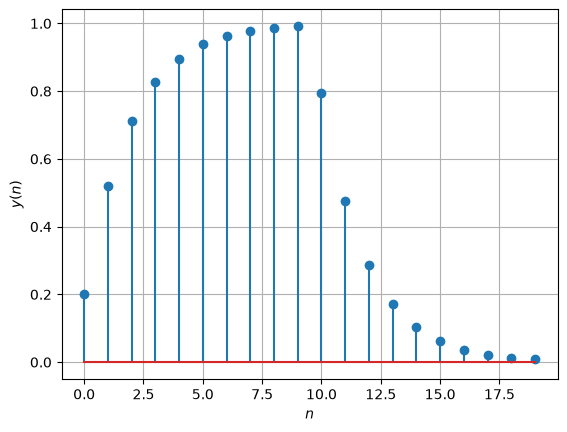

In [52]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
n = np.arange(len(y_n))
ax.stem(n, y_n)
ax.set_xlabel('$n$')
ax.set_ylabel('$y(n)$')
plt.grid()
plt.show()

## Task 5 

### a)

In [53]:
from scipy.io import wavfile
[fs, x] = wavfile.read('tones.wav')

### b)

In [54]:
y = iir_filter(x)
filtered_audio = y

### c)

In [55]:
wavfile.write('output_tones.wav', fs, filtered_audio.astype(x.dtype))

### d)

Using Audacity, the input audio (tones) and output audio (output_tones) were compared. This software was particularly useful, as an audible effect was not very apparent from just listening. When viewed this way, it can clearly be seen that the output audio has a decreasing amplitude over time, in contrast to the input audio's constant amplitude. 

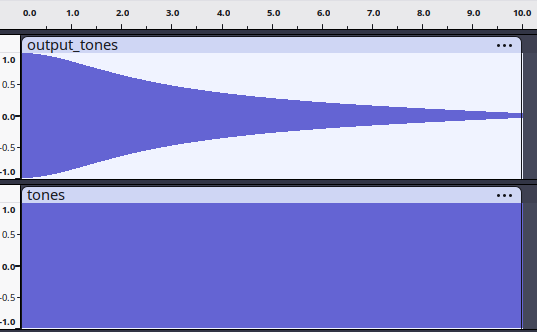

## task 6 

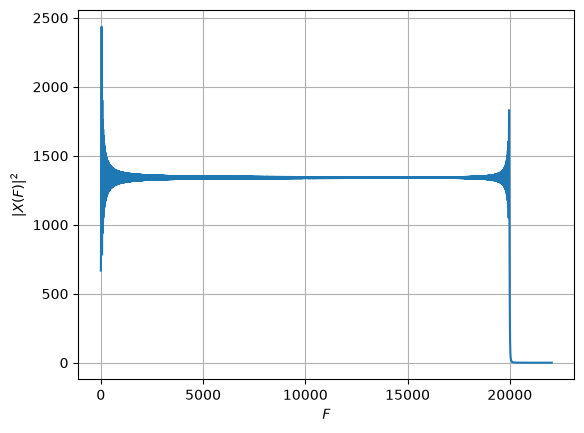

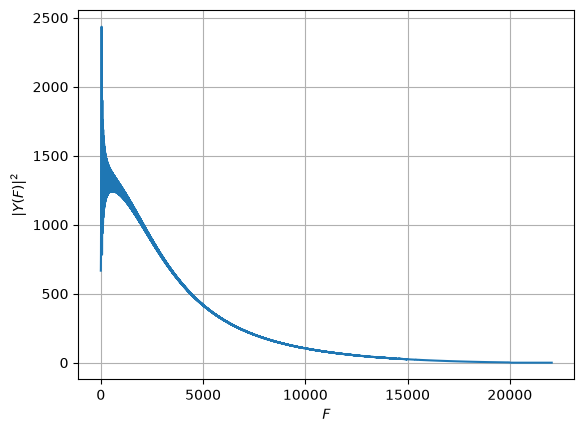

In [56]:
from scipy.fft import fft, fftfreq

X = fft(x) / len(x)
# spectrum is symmetric, so remove second half
X = X[:len(X) // 2]
Xp = np.abs(X) ** 2

# frequencies corresponding to the output of fft
F = fftfreq(len(x), 1 / fs)
F = F[:len(F) // 2]

fig, ax = plt.subplots()
ax.plot(F, Xp)
ax.set_xlabel('$F$')
ax.set_ylabel('$|X(F)|^2$')
ax.grid(True)

# Power spectrum of Y against F 
Y = fft(y) / len(y)
Y = Y[:len(Y) // 2]
Yp = np.abs(Y) ** 2

F = fftfreq(len(y), 1 / fs)
F = F[:len(F) // 2]

fig, ax = plt.subplots()
ax.plot(F,Yp)
ax.set_xlabel('$F$')
ax.set_ylabel('$|Y(F)|^2$')
ax.grid(True)

plt.show()

The output power spectrum shows greater attenuation at higher frequencies, while allowng lower frequencies to pass through; this indicates that the system is a low-pass filter. 

This corresponds with task 5d, where lower frequencies have the highest amplitude, and the amplitude steadily decreases as the tone frequency increases. 



## Task 7

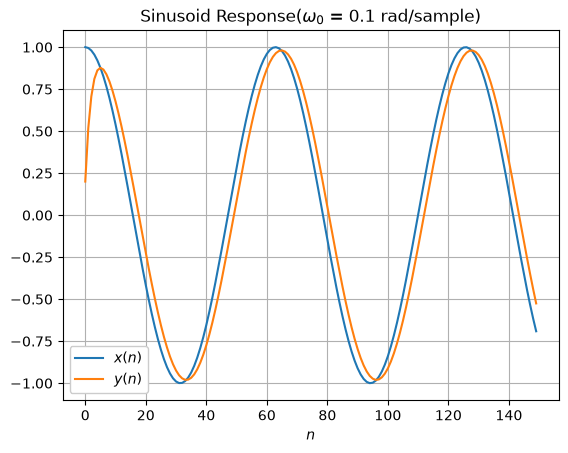

In [70]:
L = 150
w0 = 0.1

n = np.arange(L)
x = np.cos(n * w0)
y = iir_filter(x)

fig, ax = plt.subplots()
ax.plot(n, x, label='$x(n)$')
ax.plot(n, y, label='$y(n)$')
ax.set_xlabel('$n$')
ax.legend(loc='best', framealpha=1)
ax.grid(True)
plt.title("Sinusoid Response($\\omega_0$ = 0.1 rad/sample)")
plt.show()

### Gain
The Amplitudes of the output and input can be seen via zooming in on the above plot as shown below.

$$Gain =\frac{\text{output amplitude}}{\text{input amplitude}}$$

$$Gain =\frac{0.98}{1} = 0.98$$

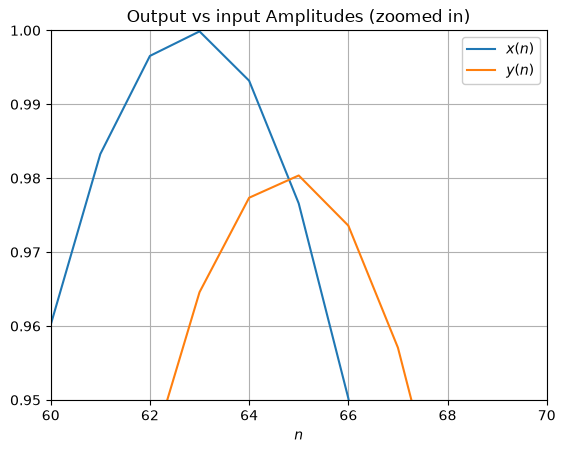

In [74]:
fig, ax = plt.subplots()
ax.plot(n, x, label='$x(n)$')
ax.plot(n, y, label='$y(n)$')
ax.set_xlabel('$n$')
ax.legend(loc='best', framealpha=1)
ax.grid(True)
ax.set_xlim(60,70)
ax.set_ylim(0.95,1)
plt.title("Output vs input Amplitudes (zoomed in)")
plt.show()

### Phase Shift
$$Phase shift = -w_0 \times delay = -0.1 \times delay$$
$$delay=n_{\text{output crossing}}-n_{\text{input crossing}}$$

From the graph below, for the chosen segment, we can see that: 

$$n_{\text{output crossing}} \approx 80.5 $$
$$n_{\text{input crossing}} \approx 78.5 $$

Therefore: 

$$delay \approx 80.5 - 78.5 \approx 2$$
$$Phase shift \approx -w_0 \times 2 = -0.1 \times 2 \approx -0.2$$

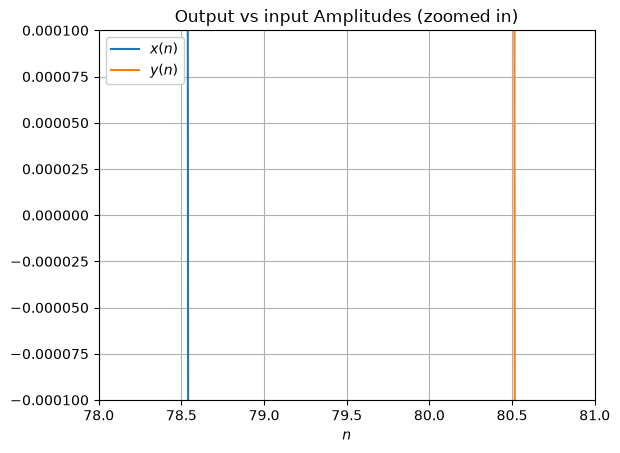

In [ ]:
fig, ax = plt.subplots()
ax.plot(n, x, label='$x(n)$')
ax.plot(n, y, label='$y(n)$')
ax.set_xlabel('$n$')
ax.legend(loc='best', framealpha=1)
ax.grid(True)
ax.set_xlim(78,81)
ax.set_ylim(-0.0001,0.0001)

plt.title("Output vs input zero crossings (zoomed in)")
plt.show()

## Task 8

Frequency: 0.1000 rad/sample
Input amplitude: 1.0000, Output amplitude: 0.9805
Input crossing: 78.5398, Output crossing: 80.5154
Gain = 0.9805 / 1.0000 = 0.9806
Delay = 80.5154 - 78.5398 = 1.9756 samples
Phase = -0.1000 x 1.9756 = -0.1976 rad

Frequency: 0.1467 rad/sample
Input amplitude: 1.0000, Output amplitude: 0.9594
Input crossing: 53.5475, Output crossing: 55.4963
Gain = 0.9594 / 1.0000 = 0.9595
Delay = 55.4963 - 53.5475 = 1.9488 samples
Phase = -0.1467 x 1.9488 = -0.2858 rad

Frequency: 0.2151 rad/sample
Input amplitude: 1.0000, Output amplitude: 0.9180
Input crossing: 65.7140, Output crossing: 67.6095
Gain = 0.9180 / 1.0000 = 0.9180
Delay = 67.6095 - 65.7140 = 1.8955 samples
Phase = -0.2151 x 1.8955 = -0.4078 rad

Frequency: 0.3155 rad/sample
Input amplitude: 1.0000, Output amplitude: 0.8437
Input crossing: 44.8020, Output crossing: 46.5988
Gain = 0.8437 / 1.0000 = 0.8437
Delay = 46.5988 - 44.8020 = 1.7969 samples
Phase = -0.3155 x 1.7969 = -0.5670 rad

Frequency: 0.4628 rad/sa

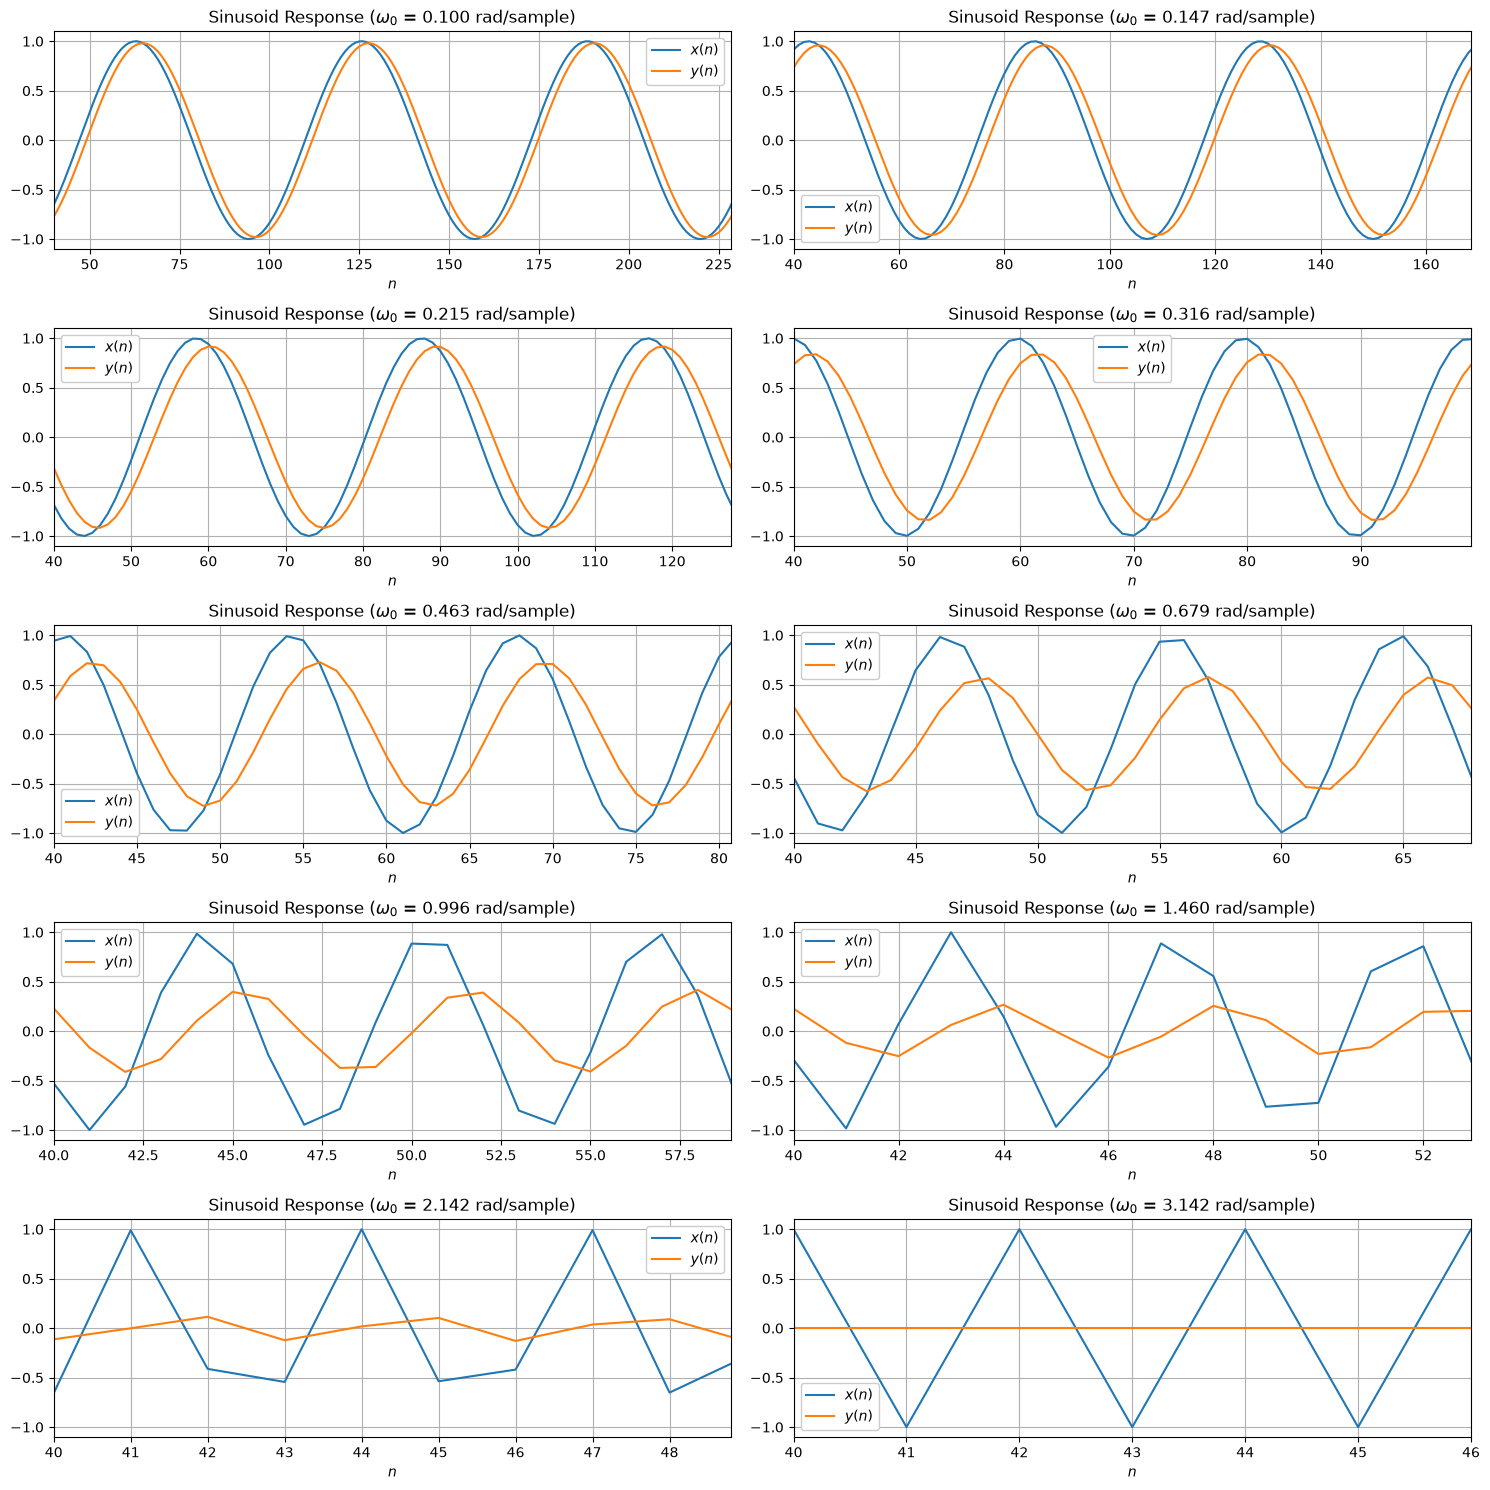

Gains: [np.float64(0.9805653594901436), np.float64(0.959455146599711), np.float64(0.9179657608812621), np.float64(0.8436583122918756), np.float64(0.7277228518183002), np.float64(0.5778766753815542), np.float64(0.41792455567661774), np.float64(0.26898734974379734), np.float64(0.13526190633838595), np.float64(2.673498922245443e-10)]
Phase shifts: [np.float64(-0.19755798874819563), np.float64(-0.2858395391534572), np.float64(-0.4077811062246334), np.float64(-0.5669816643577917), np.float64(-0.752865467313647), np.float64(-0.9571349419375779), np.float64(-1.1427475816028934), np.float64(-1.247032748248705), np.float64(-1.6652495899575512), np.float64(-6.231314398040024)]


In [ ]:
freqs = np.geomspace(0.1, np.pi, 10)

L = 250
n = np.arange(L)

gains = []
phase_shifts = []

fig, axes = plt.subplots(5, 2, figsize=(15, 15))

for i in range(len(freqs)):
    ax = axes.flat[i]
    w0 = freqs[i]
    x = np.cos(n * w0)
    y = iir_filter(x)

    ax.plot(n, x, label='$x(n)$')
    ax.plot(n, y, label='$y(n)$')
    ax.set_xlabel('$n$')
    ax.set_xlim(40, 40 + 3 * 2 * np.pi / w0)  # show 3 cycles per subplot
    ax.legend(loc='best', framealpha=1)
    ax.grid(True)
    ax.set_title(rf'Sinusoid Response ($\omega_0$ = {w0:.3f} rad/sample)')

    # Measure Amplitudes
    Ax = np.max(np.abs(x[40:]))
    Ay = np.max(np.abs(y[40:]))

    # Find input crossing
    for k in range(40, L-1):
        if x[k] >= 0 and x[k+1] < 0: # a zero must lie between a + and a -
            nx = k + x[k] / (x[k] - x[k+1]) # interpolation
            break
    # find output crossing
    for k in range(int(nx), L-1):
        if y[k] >= 0 and y[k+1] < 0:
            ny = k + y[k] / (y[k] - y[k+1])
            break

    gain = Ay / Ax
    delay = ny - nx
    phase_shift = -w0 * delay 

    if gain > 1e-8:
        print(
            f"Frequency: {w0:.4f} rad/sample\n"
            f"Input amplitude: {Ax:.4f}, Output amplitude: {Ay:.4f}\n"
            f"Input crossing: {nx:.4f}, Output crossing: {ny:.4f}\n"
            f"Gain = {Ay:.4f} / {Ax:.4f} = {gain:.4f}\n"
            f"Delay = {ny:.4f} - {nx:.4f} = {delay:.4f} samples\n"
            f"Phase = -{w0:.4f} x {delay:.4f} = {phase_shift:.4f} rad\n"
        )

    gains.append(gain)
    phase_shifts.append(phase_shift)


fig.tight_layout()
plt.show()

print("Gains:", gains)
print("Phase shifts:", phase_shifts)

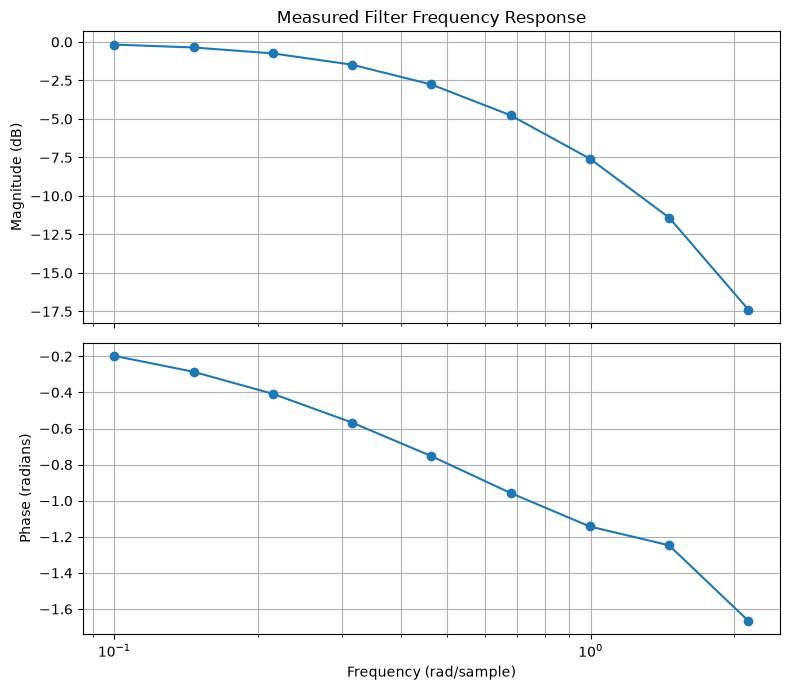

In [133]:
gains = np.array(gains)
phase_shifts = np.array(phase_shifts)

# Exclude the effectively zero-gain point
valid_gains = gains > 1e-8

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

axes[0].semilogx(freqs[valid_gains], 20 * np.log10(gains[valid_gains]), 'o-')
axes[0].set_title('Measured Filter Frequency Response')
axes[0].set_ylabel('Magnitude (dB)')
axes[0].grid(True, which = 'both')

axes[1].semilogx(freqs[valid_gains], phase_shifts[valid_gains], 'o-')
axes[1].set_ylabel('Phase (radians)')
axes[1].set_xlabel('Frequency (rad/sample)')
axes[1].grid(True, which = 'both')

plt.tight_layout()
plt.show()